# Exercice 2 — Implémenter un mini-GPT pour générer du texte

**Objectif :** construire depuis zéro un Transformer **autorégressif** qui prédit le **prochain caractère**.

- Tokenisation par caractères (vocabulaire = caractères du corpus)
- 2 blocs GPT, 4 têtes, dimension 64, MLP 64 → 256 → 64 (GELU), contexte de 64 caractères
- Perte d'entropie croisée sur **toutes** les positions
- Génération de 200 caractères avec différentes températures

In [1]:
from pathlib import Path
import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

## 1. Données : `corpus.txt` et vocabulaire

In [2]:
chemin = next(p for p in [Path("../data/corpus.txt"), Path("data/corpus.txt"), Path("corpus.txt")] if p.exists())

with open(chemin, encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
taille_vocabulaire = len(caracteres)

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

print("Caractères dans le corpus :", len(texte))
print("Taille du vocabulaire     :", taille_vocabulaire)
print("Vocabulaire :", "".join(caracteres).replace("\n", "\\n"))

Caractères dans le corpus : 5161
Taille du vocabulaire     : 55
Vocabulaire : \n ',-.:ABCDEGHILMOPRSTUabcdefghijklmnopqrstuvxyzÀàâèéêî


In [3]:
def encoder(s):
    return [stoi[c] for c in s]


def decoder(ids):
    return "".join(itos[int(i)] for i in ids)


# Exemple d'une paire entrée/cible : la cible est l'entrée décalée d'un caractère.
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]
print("Entrée :", repr(decoder(x[:30])))
print("Cible  :", repr(decoder(y[:30])))

Entrée : 'Le matin, la ville se réveille'
Cible  : 'e matin, la ville se réveille '


In [4]:
# Découpage : 90 % pour l'entraînement, 10 % (fin du texte) pour la validation.
coupure = int(0.9 * len(tokens))
train_tokens, val_tokens = tokens[:coupure], tokens[coupure:]


def lot(source, batch_size=64, longueur=64):
    """Tire des fenêtres aléatoires : x = tokens[i:i+L], y = tokens[i+1:i+L+1]."""
    debuts = torch.randint(0, len(source) - longueur - 1, (batch_size,))
    xb = torch.stack([source[d:d + longueur] for d in debuts])
    yb = torch.stack([source[d + 1:d + longueur + 1] for d in debuts])
    return xb, yb


xb, yb = lot(train_tokens)
print("Identifiants en entrée :", tuple(xb.shape), "| cibles :", tuple(yb.shape))

Identifiants en entrée : (64, 64) | cibles : (64, 64)


## 2. Le bloc GPT

```
x ──► LayerNorm ──► Attention multi-têtes causale ──► (+) ──► LayerNorm ──► MLP 64→256→64 (GELU) ──► (+) ──►
│                                                      ▲  │                                            ▲
└──────────────────────── connexion résiduelle ────────┘  └──────────── connexion résiduelle ──────────┘
```

Masque causal (`True` = relation d'attention interdite) : la position *t* ne peut regarder que les positions ≤ *t*.

In [5]:
def masque_causal(T, device=None):
    # True signifie : cette relation d'attention est interdite
    return torch.triu(torch.ones(T, T, dtype=torch.bool, device=device), diagonal=1)


print(masque_causal(5).int())

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


In [6]:
class BlocGPT(nn.Module):
    def __init__(self, d_model=64, nhead=4, d_mlp=256, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_mlp),
            nn.GELU(),
            nn.Linear(d_mlp, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        T = x.shape[1]
        h = self.ln1(x)                                             # 1. LayerNorm avant l'attention
        a, _ = self.attention(h, h, h, attn_mask=masque_causal(T, x.device),
                              need_weights=False)                   # 2. attention causale
        x = x + a                                                   # 3. connexion résiduelle
        x = x + self.mlp(self.ln2(x))                               # 4-6. LayerNorm + MLP + résiduel
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=64, d_model=64, nhead=4, n_blocs=2, dropout=0.1):
        super().__init__()
        self.longueur_max = longueur_max
        self.tok_emb = nn.Embedding(taille_vocabulaire, d_model)    # embeddings de caractères
        self.pos_emb = nn.Embedding(longueur_max, d_model)          # embeddings de positions
        self.drop = nn.Dropout(dropout)
        self.blocs = nn.ModuleList([BlocGPT(d_model, nhead, 4 * d_model, dropout) for _ in range(n_blocs)])
        self.ln_f = nn.LayerNorm(d_model)
        self.tete = nn.Linear(d_model, taille_vocabulaire)          # projection vers le vocabulaire

    def forward(self, ids):
        B, T = ids.shape
        pos = torch.arange(T, device=ids.device)
        x = self.drop(self.tok_emb(ids) + self.pos_emb(pos))        # (B, T, 64)
        for bloc in self.blocs:
            x = bloc(x)
        return self.tete(self.ln_f(x))                              # (B, T, vocabulaire)


modele = MiniGPT(taille_vocabulaire)
print("Paramètres :", sum(p.numel() for p in modele.parameters()))

with torch.no_grad():
    modele.eval()
    representations = modele.tok_emb(xb) + modele.pos_emb(torch.arange(64))
    print("Identifiants en entrée :", tuple(xb.shape))
    print("Représentations        :", tuple(representations.shape))
    print("Logits                 :", tuple(modele(xb).shape))
    print("Cibles                 :", tuple(yb.shape))

Paramètres : 111287
Identifiants en entrée : (64, 64)
Représentations        : (64, 64, 64)
Logits                 : (64, 64, 55)
Cibles                 : (64, 64)


## 3. Vérification essentielle : la causalité

En mode `eval()`, modifier un caractère **futur** ne doit pas modifier les logits des positions **précédentes**.

In [7]:
def verifier_causalite(modele, position=40):
    modele.eval()
    ids = val_tokens[:64].unsqueeze(0).clone()
    modifie = ids.clone()
    modifie[0, position] = (modifie[0, position] + 1) % taille_vocabulaire
    with torch.no_grad():
        l1, l2 = modele(ids), modele(modifie)
    avant = torch.allclose(l1[:, :position], l2[:, :position], atol=1e-6)
    apres = not torch.allclose(l1[:, position:], l2[:, position:], atol=1e-6)
    print(f"Positions < {position} inchangées : {avant}")
    print(f"Positions ≥ {position} modifiées  : {apres}")
    return avant and apres


assert verifier_causalite(modele), "fuite d'information du futur !"

Positions < 40 inchangées : True
Positions ≥ 40 modifiées  : True


## 4. Entraînement (entropie croisée sur toutes les positions)

In [8]:
@torch.no_grad()
def perte_moyenne(modele, source, n_lots=20):
    modele.eval()
    pertes = []
    for _ in range(n_lots):
        xb, yb = lot(source)
        logits = modele(xb)
        pertes.append(F.cross_entropy(logits.reshape(-1, taille_vocabulaire), yb.reshape(-1)).item())
    modele.train()
    return sum(pertes) / len(pertes)


torch.manual_seed(42)
modele = MiniGPT(taille_vocabulaire, dropout=0.2)
optimiseur = torch.optim.AdamW(modele.parameters(), lr=3e-3, weight_decay=0.1)
n_etapes = 1500
historique = {"etape": [], "train": [], "val": []}
meilleure_val, meilleur_etat, meilleure_etape = float("inf"), None, 0

debut = time.time()
modele.train()
for etape in range(1, n_etapes + 1):
    xb, yb = lot(train_tokens)
    logits = modele(xb)                                                  # (B, 64, V)
    perte = F.cross_entropy(logits.reshape(-1, taille_vocabulaire),      # (B*64, V)
                            yb.reshape(-1))                              # (B*64,)
    optimiseur.zero_grad()
    perte.backward()
    torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
    optimiseur.step()

    if etape % 100 == 0 or etape == 1:
        pt, pv = perte_moyenne(modele, train_tokens), perte_moyenne(modele, val_tokens)
        historique["etape"].append(etape)
        historique["train"].append(pt)
        historique["val"].append(pv)
        marque = ""
        if pv < meilleure_val:   # conserver le modèle ayant la meilleure perte de validation
            meilleure_val, meilleure_etape = pv, etape
            meilleur_etat = {k: v.clone() for k, v in modele.state_dict().items()}
            marque = "  <- meilleur"
        print(f"Étape {etape:4d} | train {pt:.3f} | val {pv:.3f} | {time.time() - debut:5.1f}s{marque}")

modele.load_state_dict(meilleur_etat)
print(f"\nModèle conservé : étape {meilleure_etape} (val = {meilleure_val:.3f})")
print(f"Référence : perte d'un modèle uniforme = ln({taille_vocabulaire}) = {math.log(taille_vocabulaire):.3f}")

Étape    1 | train 3.842 | val 3.851 |   0.8s  <- meilleur


Étape  100 | train 2.243 | val 2.335 |  11.8s  <- meilleur


Étape  200 | train 1.969 | val 2.181 |  25.8s  <- meilleur


Étape  300 | train 1.631 | val 2.031 |  34.2s  <- meilleur


Étape  400 | train 1.322 | val 1.956 |  41.9s  <- meilleur


Étape  500 | train 1.014 | val 1.962 |  49.8s


... (6 outputs left out)

Étape 1200 | train 0.259 | val 2.556 | 105.8s


Étape 1300 | train 0.239 | val 2.599 | 115.2s


Étape 1400 | train 0.224 | val 2.711 | 124.9s


Étape 1500 | train 0.216 | val 2.711 | 134.5s

Modèle conservé : étape 400 (val = 1.956)
Référence : perte d'un modèle uniforme = ln(55) = 4.007


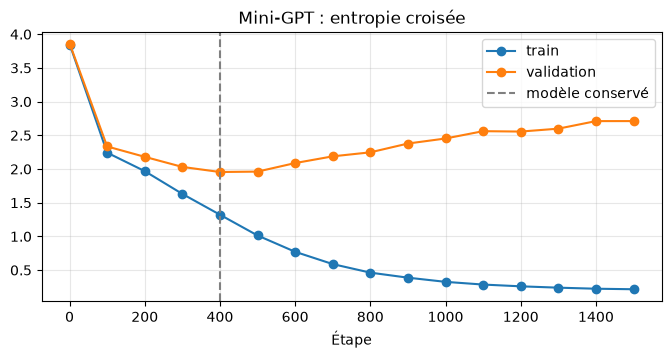

Positions < 40 inchangées : True
Positions ≥ 40 modifiées  : True


In [9]:
plt.figure(figsize=(8, 3.5))
plt.plot(historique["etape"], historique["train"], marker="o", label="train")
plt.plot(historique["etape"], historique["val"], marker="o", label="validation")
plt.axvline(meilleure_etape, color="gray", linestyle="--", label="modèle conservé")
plt.title("Mini-GPT : entropie croisée")
plt.xlabel("Étape")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

assert verifier_causalite(modele)

## 5. Génération de 200 caractères

À chaque pas : on garde les 64 derniers caractères, on calcule les logits de la **dernière** position,
on divise par la température, on applique softmax, puis on **échantillonne** le caractère suivant.

In [10]:
@torch.no_grad()
def generer(modele, amorce, n_caracteres=200, temperature=1.0, graine=0):
    torch.manual_seed(graine)
    modele.eval()
    ids = torch.tensor([encoder(amorce)], dtype=torch.long)
    for _ in range(n_caracteres):
        contexte = ids[:, -modele.longueur_max:]
        logits = modele(contexte)[:, -1, :] / temperature
        probas = F.softmax(logits, dim=-1)
        suivant = torch.multinomial(probas, num_samples=1)
        ids = torch.cat([ids, suivant], dim=1)
    return decoder(ids[0])


amorce = "Le matin, la ville "
print(generer(modele, amorce, temperature=1.0))

Le matin, la ville se sombèt pordihe te, luire un modèle trant et le pautours dé vécilles. L'est lexières du phrait se remplongement dorment pourtine que, ce un une se pormailleuse et le les rompours des. On du seoles m


## 6. Comparaison des températures 0.5, 1.0 et 1.5

In [11]:
for t in [0.5, 1.0, 1.5]:
    print(f"========== température = {t} ==========")
    print(generer(modele, "Un modèle de type GPT ", temperature=t, graine=1))
    print()

========== température = 0.5 ==========


Un modèle de type GPT de de le dont trave les trent pour de faitions des, et les res seaux des remplont. Ces réséqu'iliers regau portes, il de les ses les écomplus modèles ses sont les réseaux de des des des étoux des couv

========== température = 1.0 ==========


Un modèle de type GPT donnne lentagne apprent der fainfé confamprombine, le un l'éte sits, il champrombits, que épui dil le confappous ée chel, combiche touvelles mar, et che revivent ents, et à le couchainféciont. Les lés

========== température = 1.5 ==========


Un modèle de type GPT donnne lenmatité, devent pendrendê il famit du amante un, le à bitrécict lont,mentts, quanéper iila recgcir Haus éest denn oux flestanféCacs mar, ettexe rejodèlegeryorrAs son écouchaqu'éciont. Les lés



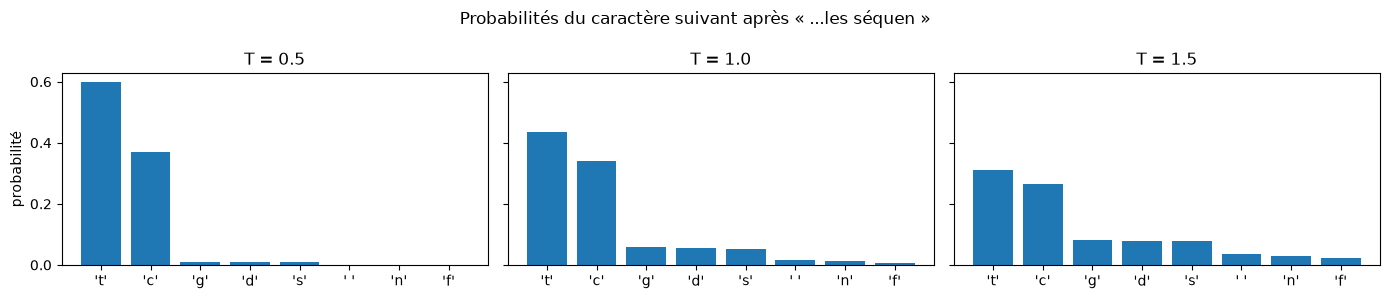

In [12]:
# Effet de la température sur la distribution du prochain caractère
with torch.no_grad():
    ids = torch.tensor([encoder("Le Transformer a changé la manière de traiter les séquen")])
    logits = modele(ids)[0, -1]

fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, t in zip(axes, [0.5, 1.0, 1.5]):
    p = F.softmax(logits / t, dim=-1)
    top = torch.topk(p, 8)
    ax.bar([repr(itos[i.item()]) for i in top.indices], top.values)
    ax.set_title(f"T = {t}")
axes[0].set_ylabel("probabilité")
plt.suptitle("Probabilités du caractère suivant après « ...les séquen »")
plt.tight_layout()
plt.show()

## 7. Questions

**Constat préalable : surapprentissage.** Le corpus ne contient qu'environ 5 000 caractères. La perte d'entraînement continue de baisser (≈ 0.2), mais la perte de validation remonte après ≈ 400 étapes : au-delà, le modèle **récite** le corpus. C'est pour cela qu'on conserve le modèle ayant la meilleure perte de validation (≈ 1.96, contre ln(55) ≈ 4.0 pour un modèle qui tirerait les caractères au hasard). Le modèle conservé a appris l'orthographe locale, les espaces, la ponctuation et des mots fréquents (« les », « modèle », « réseaux »), mais pas le sens. Un corpus plus grand corrigerait ce problème.

**Que se passe-t-il pendant l'entraînement si le masque causal est supprimé ?**
La position *t* doit prédire le caractère *t+1*, qui se trouve aussi dans l'entrée à la position *t+1*. Sans masque, l'attention peut lire directement ce caractère futur : le modèle apprend à **copier** la réponse au lieu de la prédire. La perte d'entraînement tombe presque à zéro, mais le modèle est inutilisable en génération, car au moment de générer le futur n'existe pas encore. La vérification de causalité (modifier un caractère futur ne change pas les logits passés) échouerait.

**Quel effet la température a-t-elle sur la génération ?**
Les logits sont divisés par *T* avant le softmax.
- *T* < 1 (0.5) : la distribution devient plus « pointue ». Le modèle choisit presque toujours les caractères les plus probables, d'où un texte plus régulier mais répétitif (« de de le... », « des des des »).
- *T* = 1 : on échantillonne la distribution apprise telle quelle.
- *T* > 1 (1.5) : la distribution s'aplatit. Des caractères peu probables sont tirés (majuscules au milieu des mots, lettres isolées), et le texte devient plus varié mais incohérent.

Le graphique des probabilités du caractère suivant montre cet aplatissement directement.

**Pourquoi faut-il décaler les cibles d'une position ?**
Parce que l'objectif est de prédire le **caractère suivant** : la sortie à la position *t* doit être comparée au caractère *t+1* (`y = tokens[1:L+1]` pour `x = tokens[0:L]`). Avec ce décalage et le masque causal, une seule séquence de 64 caractères fournit 64 exemples d'entraînement en parallèle (prédire *x₁* à partir de *x₀*, *x₂* à partir de *x₀x₁*, etc.). Sans décalage, la cible serait le caractère d'entrée lui-même et le modèle apprendrait une simple copie.
